In [1]:
import pandas as pd

# Load dataset
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

# 1. Drop customerID (has no predictive value)
df.drop(columns=['customerID'], inplace=True)

# 2. Convert TotalCharges from string to numeric (force blank spaces to NaN)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce')

# 3. Impute missing values with the median
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

# 4. Encode target: 'Yes' -> 1 (Churn), 'No' -> 0 (Retained)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

print("Dataset Shape:", df.shape)
print("Class Imbalance Ratio:\n", df['Churn'].value_counts(normalize=True))

Dataset Shape: (7043, 20)
Class Imbalance Ratio:
 Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64


/tmp/ipykernel_846/3050496485.py:14: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# Separate features (X) and target label (y)
X = df.drop(columns=['Churn'])
y = df['Churn'].values

# Identify column types automatically
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Define preprocessing pipeline for numeric & categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_cols)
    ]
)

# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set: {X_test.shape[0]} samples")

Training set: 5634 samples
Testing set: 1409 samples


In [3]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Calculate positive-class weighting scale for XGBoost
ratio = (len(y_train) - sum(y_train)) / sum(y_train)

# Build end-to-end pipelines to prevent data leakage
models = {
    "Random Forest (with SMOTE)": ImbPipeline([
        ('preprocessor', preprocessor),
        ('smote', SMOTE(random_state=42)),
        ('classifier', RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42))
    ]),
    "XGBoost (Weighted)": ImbPipeline([
        ('preprocessor', preprocessor),
        ('classifier', XGBClassifier(
            n_estimators=150,
            learning_rate=0.05,
            max_depth=4,
            scale_pos_weight=ratio,
            eval_metric='logloss',
            random_state=42
        ))
    ])
}


--- Random Forest (with SMOTE) Performance ---
ROC-AUC Score: 0.8407
              precision    recall  f1-score   support

           0       0.88      0.78      0.83      1035
           1       0.54      0.70      0.61       374

    accuracy                           0.76      1409
   macro avg       0.71      0.74      0.72      1409
weighted avg       0.79      0.76      0.77      1409


--- XGBoost (Weighted) Performance ---
ROC-AUC Score: 0.8430
              precision    recall  f1-score   support

           0       0.91      0.73      0.81      1035
           1       0.51      0.80      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



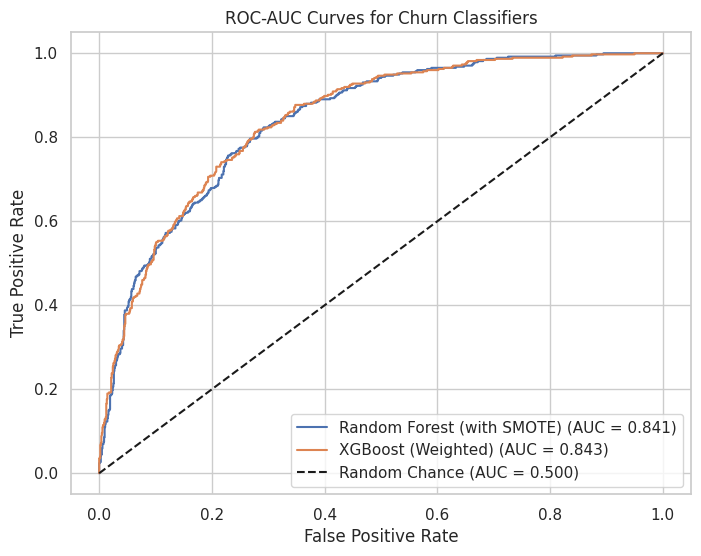

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, roc_curve, classification_report

# Set style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 6))

for name, model_pipeline in models.items():
    # 1. Fit pipeline on training data
    model_pipeline.fit(X_train, y_train)

    # 2. Predict churn probabilities for ROC curve
    y_proba = model_pipeline.predict_proba(X_test)[:, 1]
    y_pred = model_pipeline.predict(X_test)

    # 3. Calculate ROC-AUC Score
    auc_score = roc_auc_score(y_test, y_proba)
    print(f"\n--- {name} Performance ---")
    print(f"ROC-AUC Score: {auc_score:.4f}")
    print(classification_report(y_test, y_pred))

    # 4. Plot ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.3f})")

# Format plot
plt.plot([0, 1], [0, 1], 'k--', label="Random Chance (AUC = 0.500)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Curves for Churn Classifiers")
plt.legend(loc="lower right")
plt.show()

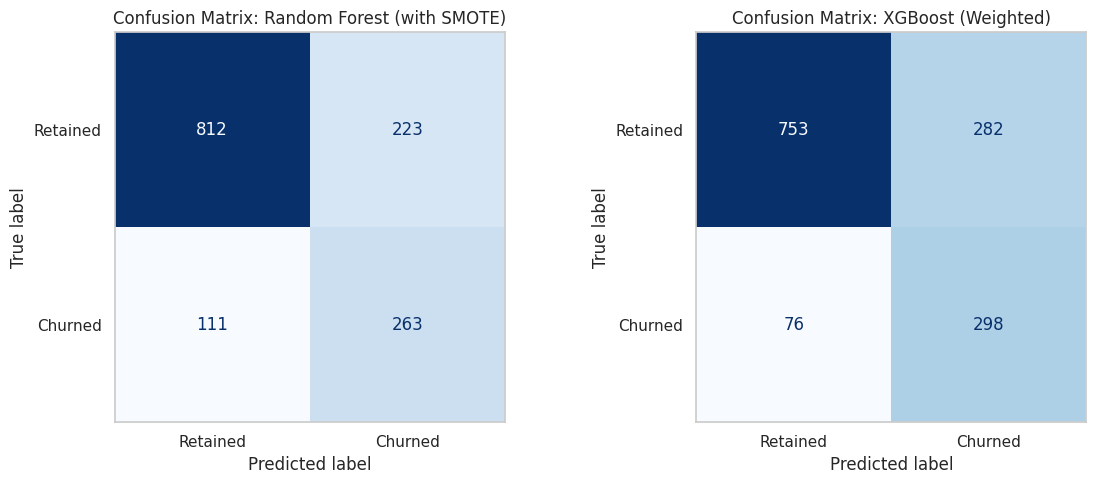

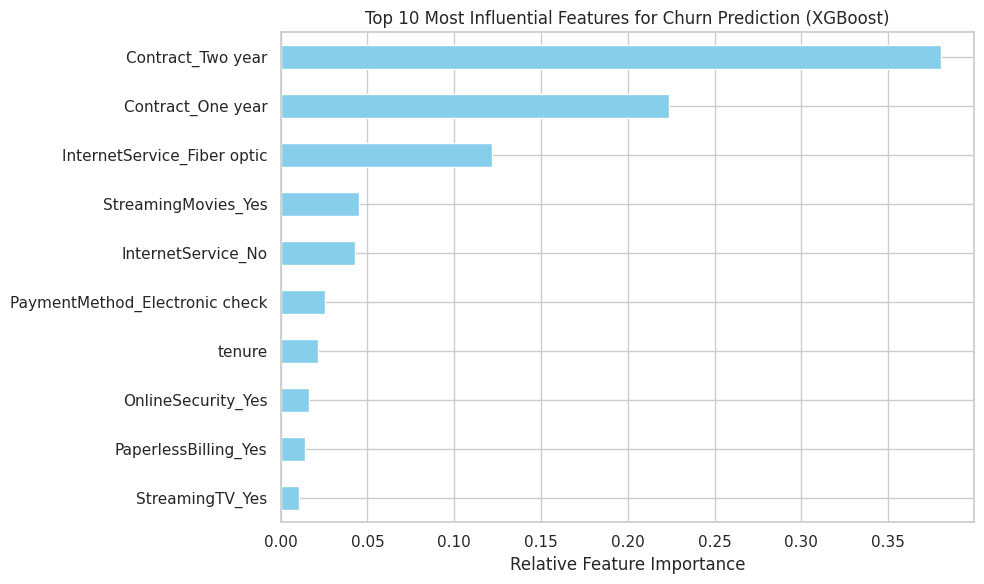

In [5]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# ---------------------------------------------------------
# Part A: Plot Confusion Matrices
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for idx, (name, model_pipeline) in enumerate(models.items()):
    y_pred = model_pipeline.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Retained', 'Churned'])
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False)
    axes[idx].set_title(f"Confusion Matrix: {name}")
    axes[idx].grid(False)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Part B: Extract & Plot Top 10 Feature Importances (XGBoost)
# ---------------------------------------------------------
best_model = models["XGBoost (Weighted)"]

# Reconstruct feature names post OneHotEncoding
feature_names = (
    numerical_cols +
    list(best_model.named_steps['preprocessor']
         .named_transformers_['cat']
         .get_feature_names_out(categorical_cols))
)

# Extract feature importance weights
importances = best_model.named_steps['classifier'].feature_importances_
feature_series = pd.Series(importances, index=feature_names).sort_values(ascending=False)

# Plot top 10 features
plt.figure(figsize=(10, 6))
feature_series.head(10).plot(kind='barh', color='skyblue').invert_yaxis()
plt.title("Top 10 Most Influential Features for Churn Prediction (XGBoost)")
plt.xlabel("Relative Feature Importance")
plt.tight_layout()
plt.show()